In [31]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_DIR = Path("data")
N_REPS = 5
TRIM_FIRST_MS = 10

CONFIG = {
    "R1": {
        "threshold_uA": 1000,
        "smooth_ms": 200,
        "min_active_ms": 1000,
        "cycle_index": 1,       # Second to third active event
        "sleep_last_ms": 5000,
    },
    "R2": {
        "threshold_uA": 5000,
        "smooth_ms": 101,
        "min_active_ms": 5000,
        "cycle_index": 0,       # First to second active event
        "sleep_last_ms": 5000,
    },
}


def detect_active_periods(df, config):

    t = df["timestamp_ms"].to_numpy()
    current = df["current_uA"]

    active = (current >= config["threshold_uA"]).astype(float)

    smoothed = active.rolling(
        window=config["smooth_ms"],
        center=True,
        min_periods=1
    ).mean()

    mask = smoothed.to_numpy() > 0.8

    edges = np.diff(
        np.r_[False, mask, False].astype(int)
    )

    starts = np.where(edges == 1)[0]
    ends = np.where(edges == -1)[0]

    periods = []

    for start, end in zip(starts, ends):

        start_ms = int(t[start])
        end_ms = int(t[end - 1]) + 1

        if end_ms - start_ms >= config["min_active_ms"]:
            periods.append((start_ms, end_ms))

    return periods


def add_charge(df):

    df = df.copy()

    # PPK2 sampling interval = 1 ms
    dt_ms = df["timestamp_ms"].diff().fillna(1)

    df["charge_cumulative_uAh"] = (
        df["current_uA"] * dt_ms / 3_600_000
    ).cumsum()

    return df


all_summaries = []

for configuration, config in CONFIG.items():

    output_dir = DATA_DIR / f"{configuration.lower()}_cleaned"
    output_dir.mkdir(parents=True, exist_ok=True)

    master_cycles = []
    summaries = []

    print(f"\nProcessing {configuration}...")

    for rep in range(1, N_REPS + 1):

        file_path = (
            DATA_DIR / f"Radio_{configuration}_{rep}_rep.csv"
        )

        df = pd.read_csv(file_path)

        df = df.rename(columns={
            "Timestamp(ms)": "timestamp_ms",
            "Current(uA)": "current_uA"
        })

        df = df[["timestamp_ms", "current_uA"]].copy()

        df = df.apply(pd.to_numeric, errors="coerce")
        df = df.dropna()
        df = df.sort_values("timestamp_ms")
        df = df.drop_duplicates("timestamp_ms")

        df = df[
            df["timestamp_ms"] >= TRIM_FIRST_MS
        ].reset_index(drop=True)

        # Validate 1-ms sampling
        timestamps = df["timestamp_ms"].to_numpy()

        if not np.all(np.diff(timestamps) == 1):
            raise ValueError(
                f"{file_path.name}: Nonuniform sampling detected"
            )


        periods = detect_active_periods(df, config)

        index = config["cycle_index"]

        if len(periods) < index + 2:
            raise ValueError(
                f"{file_path.name}: Insufficient active periods. "
                f"Detected: {periods}"
            )

        cycle_start = periods[index][0]
        cycle_end = periods[index + 1][0]


        cycle = df[
            (df["timestamp_ms"] >= cycle_start) &
            (df["timestamp_ms"] < cycle_end)
        ].copy()

        cycle["configuration"] = configuration
        cycle["replicate"] = rep

        cycle["cycle_time_ms"] = (
            cycle["timestamp_ms"] - cycle_start
        )

        cycle["cycle_time_s"] = (
            cycle["cycle_time_ms"] / 1000
        )

        cycle = add_charge(cycle)

        master_cycles.append(cycle)


        cycle_duration_ms = cycle_end - cycle_start

        sleep = cycle[
            cycle["cycle_time_ms"] >=
            cycle_duration_ms - config["sleep_last_ms"]
        ]

        sleep_current = sleep["current_uA"].median()


        cycle_charge = cycle["charge_cumulative_uAh"].iloc[-1]

        cycle_duration_s = cycle_duration_ms / 1000

        summaries.append({
            "configuration": configuration,
            "replicate": rep,
            "cycle_duration_s": cycle_duration_s,
            "cycle_charge_uAh": cycle_charge,
            "sleep_current_uA": sleep_current,
            "peak_current_mA": (
                cycle["current_uA"].max() / 1000
            ),
            "average_current_uA": (
                cycle_charge * 3600 / cycle_duration_s
            )
        })

        cycle.to_csv(
            output_dir /
            f"{configuration}_rep{rep}_cycle_clean.csv",
            index=False
        )

        print(
            f"Rep {rep}: "
            f"{cycle_duration_s:.3f} s, "
            f"{cycle_charge:.3f} µAh, "
            f"Sleep = {sleep_current:.3f} µA"
        )


    master = pd.concat(
        master_cycles,
        ignore_index=True
    )

    master = master[[
        "configuration",
        "replicate",
        "timestamp_ms",
        "cycle_time_ms",
        "cycle_time_s",
        "current_uA",
        "charge_cumulative_uAh"
    ]]

    master.to_csv(
        output_dir /
        f"{configuration}_master_aligned_5_replicates.csv",
        index=False
    )

    summary = pd.DataFrame(summaries)

    summary.to_csv(
        output_dir /
        f"{configuration}_replicate_summary.csv",
        index=False
    )

    all_summaries.append(summary)

    print(f"\n{configuration} Summary (mean ± SD)")

    for column in [
        "cycle_duration_s",
        "cycle_charge_uAh",
        "sleep_current_uA",
        "peak_current_mA",
        "average_current_uA"
    ]:

        print(
            f"{column}: "
            f"{summary[column].mean():.3f} ± "
            f"{summary[column].std(ddof=1):.3f}"
        )


combined_summary = pd.concat(
    all_summaries,
    ignore_index=True
)

combined_summary.to_csv(
    DATA_DIR / "R1_R2_replicate_summary.csv",
    index=False
)

print("\nProcessing complete.")


Processing R1...
Rep 1: 31.000 s, 51.654 µAh, Sleep = 202.026 µA
Rep 2: 31.000 s, 51.049 µAh, Sleep = 202.261 µA
Rep 3: 31.000 s, 51.671 µAh, Sleep = 202.005 µA
Rep 4: 31.000 s, 51.060 µAh, Sleep = 202.071 µA
Rep 5: 31.000 s, 51.605 µAh, Sleep = 202.135 µA

R1 Summary (mean ± SD)
cycle_duration_s: 31.000 ± 0.000
cycle_charge_uAh: 51.408 ± 0.324
sleep_current_uA: 202.100 ± 0.103
peak_current_mA: 125.677 ± 0.171
average_current_uA: 5969.955 ± 37.575

Processing R2...
Rep 1: 30.008 s, 42.168 µAh, Sleep = 2.663 µA
Rep 2: 30.009 s, 43.921 µAh, Sleep = 2.671 µA
Rep 3: 30.009 s, 42.162 µAh, Sleep = 2.672 µA
Rep 4: 30.009 s, 42.075 µAh, Sleep = 2.677 µA
Rep 5: 30.008 s, 42.177 µAh, Sleep = 2.666 µA

R2 Summary (mean ± SD)
cycle_duration_s: 30.009 ± 0.001
cycle_charge_uAh: 42.501 ± 0.795
sleep_current_uA: 2.670 ± 0.005
peak_current_mA: 121.035 ± 0.200
average_current_uA: 5098.607 ± 95.379

Processing complete.


R1: 51.139 ± 0.323 µAh (n=5)
R2: 42.478 ± 0.795 µAh (n=5)


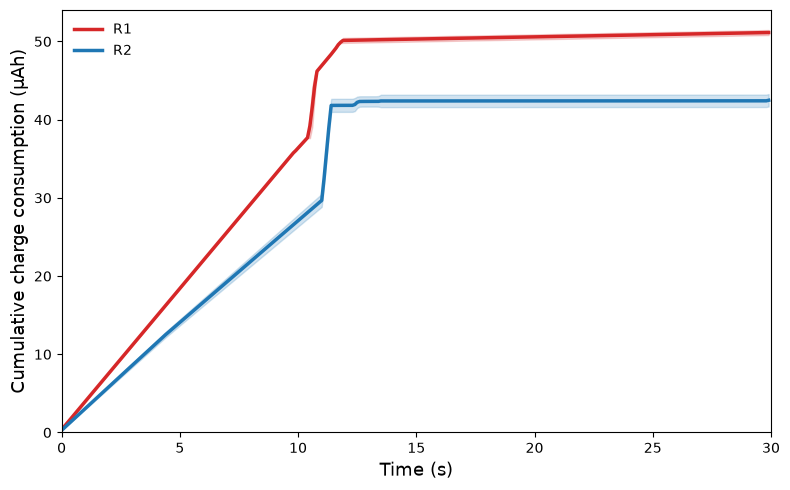

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "data"

r1 = pd.read_csv(
    f"{DATA_DIR}/r1_cleaned/R1_master_aligned_5_replicates.csv"
)
r2 = pd.read_csv(
    f"{DATA_DIR}/r2_cleaned/R2_master_aligned_5_replicates.csv"
)

def prepare_charge(df, duration=30, bin_ms=100):
    df = df.copy()

    # Common 30-second observation window
    df = df[
        (df["cycle_time_s"] >= 0) &
        (df["cycle_time_s"] < duration)
    ].copy()

    # Align all repetitions to 100-ms bins
    df["time_bin"] = (
        np.floor(df["cycle_time_s"] * 1000 / bin_ms).astype(int)
    )

    # Take the last cumulative charge value in each bin
    binned = (
        df.sort_values("cycle_time_s")
        .groupby(["replicate", "time_bin"])["charge_cumulative_uAh"]
        .last()
        .reset_index()
    )

    binned["time_s"] = binned["time_bin"] * bin_ms / 1000

    stats = (
        binned.groupby("time_s")["charge_cumulative_uAh"]
        .agg(["mean", "std", "count"])
        .reset_index()
    )

    return stats, binned


r1_stats, r1_reps = prepare_charge(r1)
r2_stats, r2_reps = prepare_charge(r2)

fig, ax = plt.subplots(figsize=(8, 5))

for stats, color, label in [
    (r1_stats, "tab:red", "R1"),
    (r2_stats, "tab:blue", "R2")
]:
    t = stats["time_s"].to_numpy()
    mean = stats["mean"].to_numpy()
    sd = stats["std"].fillna(0).to_numpy()

    ax.plot(
        t, mean,
        color=color,
        linewidth=2.5,
        label=f"{label}"
    )

    ax.fill_between(
        t, mean - sd, mean + sd,
        color=color,
        alpha=0.2
    )

ax.set_xlabel("Time (s)", fontsize=13)
ax.set_ylabel("Cumulative charge consumption (µAh)", fontsize=13)
ax.set_xlim(0, 30)
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
# ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig("Figure 3.png", dpi=600, bbox_inches="tight")
# plt.show()

# Print charge at the end of the common window
for label, reps in [("R1", r1_reps), ("R2", r2_reps)]:
    final = (
        reps.sort_values("time_bin")
        .groupby("replicate")["charge_cumulative_uAh"]
        .last()
    )

    print(
        f"{label}: {final.mean():.3f} ± "
        f"{final.std():.3f} µAh (n={len(final)})"
    )